### Proximal Policy Optimization (OpenAI, Schulman et al., 2017)

#### Отношение вероятностей сэмплинга по значимости

Суррогатная целевая функция TRPO:
$$
L_{\pi_{\boldsymbol{\theta}}}(\pi_{\tilde{\boldsymbol{\theta}}}) = \hat{\mathbb{E}}_k \left[ \frac{\pi_{\tilde{\boldsymbol{\theta}}}(a_k \mid s_k)}{\pi_{\boldsymbol{\theta}}(a_k \mid s_k)} \hat{A}_k \right] = \hat{\mathbb{E}}_k \left[ r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k \right],
$$
где $r_k(\tilde{\boldsymbol{\theta}})$ — отношение распределений:
$$
r_k(\tilde{\boldsymbol{\theta}}) = \frac{\pi_{\tilde{\boldsymbol{\theta}}}(a_k \mid s_k)}{\pi_{\boldsymbol{\theta}}(a_k \mid s_k)}.
$$

#### PPO-Clip

Для предотвращения слишком больших обновлений в PPO вводится целевая функция с оператором отсечения (клиппинга) — PPO-Clip:
$$
L^{\text{CLIP}}(\tilde{\boldsymbol{\theta}}) = \hat{\mathbb{E}}_k \left[L_k^{\text{CLIP}}(\tilde{\boldsymbol{\theta}})\right] = \hat{\mathbb{E}}_k \left[ \min\left( r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k, \operatorname{clip}(r_k(\tilde{\boldsymbol{\theta}}), 1-\varepsilon, 1+\varepsilon) \hat{A}_k \right) \right],
$$
где:
* $\varepsilon \in (0, 1)$ — гиперпараметр допустимого отклонения стратегии ($\varepsilon = 0.1$);
* $\operatorname{clip}(x, 1-\varepsilon, 1+\varepsilon) = \max(1-\varepsilon, \min(1+\varepsilon, x))$ — функция отсечения;
* Оператор минимума формирует пессимистическую нижнюю оценку на величину выигрыша.
$$
\operatorname{clip}(r_k(\tilde{\boldsymbol{\theta}}), 1-\varepsilon, 1+\varepsilon) \hat{A}_k = \begin{cases}
(1 - \varepsilon) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) < 1 - \varepsilon, \\
r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k, & 1 - \varepsilon \leqslant r_k(\tilde{\boldsymbol{\theta}}) \leqslant 1 + \varepsilon, \\
(1 + \varepsilon) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) > 1 + \varepsilon.
\end{cases}
$$

Пусть $\hat{A}_k > 0$:
$$
L_k^{\text{CLIP}}(\tilde{\boldsymbol{\theta}}) = \begin{cases}
r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) \leqslant 1 + \varepsilon, \\
(1 + \varepsilon) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) > 1 + \varepsilon.
\end{cases}
$$
$$
\nabla_{\tilde{\boldsymbol{\theta}}} L_k^{\text{CLIP}}(\tilde{\boldsymbol{\theta}}) = \begin{cases}
\hat A_k \nabla_{\tilde{\boldsymbol{\theta}}} r_k(\tilde{\boldsymbol{\theta}}), & r_k(\tilde{\boldsymbol{\theta}})\leqslant 1+\varepsilon,\\
\boldsymbol{0}, & r_k(\tilde{\boldsymbol{\theta}})>1+\varepsilon.
\end{cases}
$$

В случае $\hat{A}_k < 0$:
$$
L_k^{\text{CLIP}}(\tilde{\boldsymbol{\theta}}) = \begin{cases}
(1 - \varepsilon) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) < 1 - \varepsilon, \\
r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k, & r_k(\tilde{\boldsymbol{\theta}}) \geqslant 1 - \varepsilon,
\end{cases}
$$
$$
\nabla_{\tilde{\boldsymbol{\theta}}} L_k^{\text{CLIP}}(\tilde{\boldsymbol{\theta}}) = \begin{cases}
\boldsymbol{0}, & r_k(\tilde{\boldsymbol{\theta}}) < 1 - \varepsilon,\\
\hat A_k \nabla_{\tilde{\boldsymbol{\theta}}} r_k(\tilde{\boldsymbol{\theta}}), & r_k(\tilde{\boldsymbol{\theta}})\geqslant 1 - \varepsilon.
\end{cases}
$$
В on-policy алгоритмах собранный батч данных обычно используется для одного цикла обновления параметров стратегии. Механизм PPO-Clip позволяет увеличить эффективность использования собранных данных:

* **Обновление стратегии**
   По мере оптимизации параметры стратегии изменяются, а отношения вероятностей $r_k(\tilde{\boldsymbol\theta})$ отклоняются от единицы. В зависимости от знака преимущества оператор $\min$ ограничивает вклад тех наблюдений, для которых изменение вероятности действия становится чрезмерным.

* **Насыщение отдельных слагаемых**
   Если отношение вероятностей выходит за соответствующую границу клиппинга, градиент отдельного слагаемого целевой функции обращается в ноль. Дальнейшее изменение вероятности этого действия не влияет на целевую функцию через данное наблюдение. При этом остальные наблюдения продолжают участвовать в оптимизации.

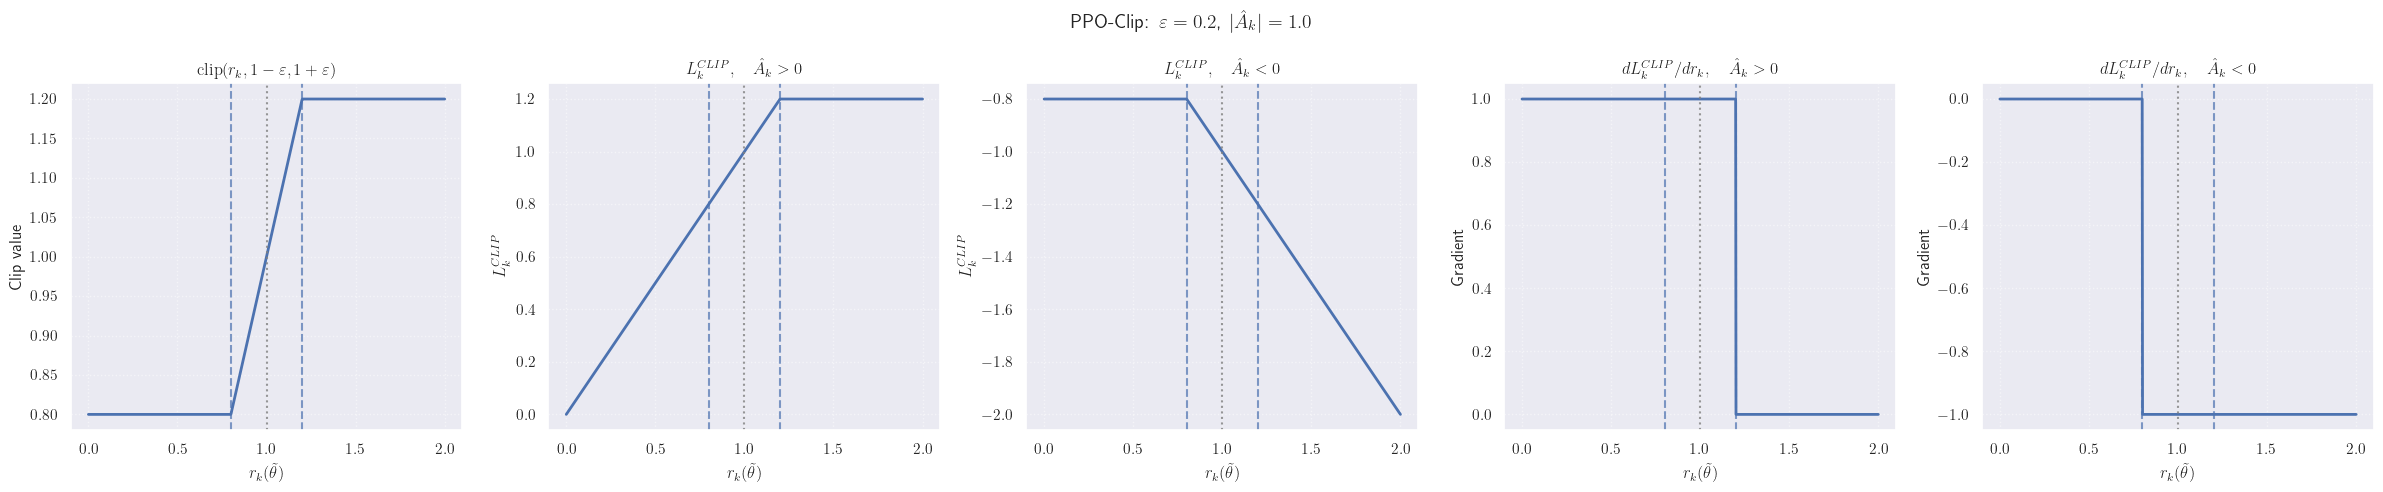

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
plt.rcParams.update({
    'text.usetex': True,
    # 'font.family': 'serif',
})
# %config InlineBackend.figure_format = 'svg'

epsilon = 0.2
A = 1.0
r = np.linspace(0, 2, 1000)

lower = 1 - epsilon
upper = 1 + epsilon
clip = np.clip(r, lower, upper)

# L_clip при A_k > 0
L_pos = np.where(r <= upper, r * A, upper * A)

# L_clip при A_k < 0
L_neg = np.where(r < lower, lower * (-A), r * (-A))

# Градиент по r при A_k > 0
grad_pos = np.where(r <= upper, A, 0.0)

# Градиент по r при A_k < 0
grad_neg = np.where(r < lower, 0.0, -A)

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

plots = [
    (clip, r"$\mathrm{clip}(r_k,1-\varepsilon,1+\varepsilon)$",
     "Clip value"),
    (L_pos, r"$L_k^{CLIP},\quad \hat A_k>0$",
     r"$L_k^{CLIP}$"),
    (L_neg, r"$L_k^{CLIP},\quad \hat A_k<0$",
     r"$L_k^{CLIP}$"),
    (grad_pos, r"$dL_k^{CLIP}/dr_k,\quad \hat A_k>0$",
     "Gradient"),
    (grad_neg, r"$dL_k^{CLIP}/d r_k,\quad \hat A_k<0$",
     "Gradient")
]

for ax, (y, title, ylabel) in zip(axes, plots):
    ax.plot(r, y, linewidth=2)

    ax.axvline(lower, linestyle="--", alpha=0.7)
    ax.axvline(1.0, linestyle=":", color="gray", alpha=0.8)
    ax.axvline(upper, linestyle="--", alpha=0.7)

    ax.set_title(title)
    ax.set_xlabel(r"$r_k(\tilde{\theta})$")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle=":", alpha=0.5)

fig.suptitle(
    rf"PPO-Clip: $\varepsilon={epsilon}$, "
    rf"$|\hat A_k|={A}$",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### PPO с адаптивным KL-штрафом (Adaptive KL Penalty)

Оптимизация суррогатной целевой функции с добавлением штрафа за отклонение новой стратегии от старой (PPO-Penalty):
$$
L^{\text{KLPEN}}(\tilde{\boldsymbol{\theta}}) = \hat{\mathbb{E}}_k \left[ r_k(\tilde{\boldsymbol{\theta}}) \hat{A}_k \right] - \beta \bar{D}_{\mathrm{KL}}(\boldsymbol{\theta} \parallel \tilde{\boldsymbol{\theta}}),
$$
где коэффициент штрафа $\beta>0$ задается как гиперпараметр, а затем динамически корректируется после каждого цикла оптимизации по правилу:
* если $\bar{D}_{\mathrm{KL}} > 1.5 d_{\text{target}}$, где $d_{\text{target}}$ — гиперпараметр, задающий целевое значение средней KL-дивергенции (в оригинальной работе $d_{\text{target}} = 0.01$), $\beta$ удваивается;
* если $\bar{D}_{\mathrm{KL}} < d_{\text{target}} / 1.5$, то значение $\beta$ уменьшается вдвое.
* в остальных случаях $\beta$ не изменяется.

Благодаря высокой эмпирической эффективности, а также простоте реализации, версия PPO-Clip получила наибольшее распространение на практике:

* **Обучение с подкреплением на основе отзывов человека (RLHF) в LLM**
В модели **InstructGPT / ChatGPT** алгоритм PPO использовался в качестве ключевого оптимизатора для выравнивания ответов языковой модели с предпочтениями человека (Ouyang et al., 2022, «Training language models to follow instructions with human feedback»).
* **Управление сложными игровыми агентами**  
Команда из пяти PPO-агентов  **OpenAI Five** обыграла действующих чемпионов мира в сложнейшую MOBA-игру с горизонтом планирования в десятки тысяч шагов (Berner et al., 2019, «Dota 2 with Large Scale Deep Reinforcement Learning»).
* **Локомоция четвероногих и двуногих роботов**  
Алгоритм PPO обучил четвероногого робота **ANYmal** (**ETH Zurich**) вставать после падений, бегать по пересечённой местности и адаптироваться к препятствиям в симуляции с успешным переносом в реальный мир (Sim-to-Real) (Hwangbo et al., 2019, «Learning agile and dynamic motor skills for legged robots», Science Robotics).
* **Библиотеки стандартных реализаций**  
Архитектурные и инженерные особенности PPO детально излагаются в открытых проектах:
    - Huang et al., 2022, «The 37 Implementation Details of Proximal Policy Optimization» (ICLR Blog Track);
    - Базовые репозитории: `CleanRL` (Raffin et al.), `Stable-Baselines3`, `Ray RLlib`.

#### Реализация PPO
$$
L^{\text{TOTAL}}(\boldsymbol{\theta}) = \frac{1}{B} \sum_{k=1}^{B}\left[ - L_k^{\text{CLIP}}(\boldsymbol{\theta}) + c_V L_k^V(\boldsymbol{\theta}) - c_H H(\pi(\cdot \mid s_k; \boldsymbol{\theta})) \right],
$$
где:
* $L_k^{\text{CLIP}}(\boldsymbol{\theta})$ — клиппированная целевая функция;
* $L_k^V(\boldsymbol{\theta})$ — функция потерь функции ценности;
* $H(\pi(\cdot \mid s_k; \boldsymbol{\theta}))$ — энтропийное слагаемое, препятствующее коллапсу стратегии;
* $c_V, c_H > 0$ — весовые коэффициенты балансировки (обычно $c_V = 0.5$, $c_H = 0.01$).

  $$
  H(\pi(\cdot \mid s; \boldsymbol{\theta})) = -\sum_{a \in \mathcal{A}} \pi(a \mid s; \boldsymbol{\theta}) \ln \pi(a \mid s; \boldsymbol{\theta}).
  $$

1. **Сбор данных**
   В $M$ параллельных средах выполняется $N$ шагов взаимодействия со средой. В результате формируется буфер опыта размера $D = M \cdot N$.
2. **Оценивание**
   Для собранных траекторий вычисляются обобщённые оценки преимущества $\hat{A}_k^{\text{GAE}(\lambda)}$​ и соответствующие целевые значения функции ценности $y_k =\hat{A}_k^{\text{GAE}(\lambda)} + V(s_k)$, используемые при обучении критика.
3. **Оптимизация**
   Следующие действия повторяются $K$ раз (число эпох оптимизации):
   * случайное перемешивание всего буфера данных;
   * разбиение буфера на мини-батчи размера $B$;
   * выполнение шага оптимизатора Adam по совместной функции потерь.
4. **Повторение цикла**
   После завершения оптимизации обновлённая стратегия используется для сбора новой порции данных, после чего цикл повторяется.

Исследования устойчивости PPO (Engstrom et al., 2020; Andrychowicz et al., 2020) показали, что результативность алгоритма обусловлена не только теоретической формулой клиппинга, но и рядом инженерных приёмов.

**Нормализация оценок преимуществ (Advantage Normalization)**

В пределах каждого оптимизируемого мини-батча оценки функции преимущества нормализуются:
$$
\hat{A}_k^{\text{norm}} = \frac{\hat{A}_k - \mu_{\hat{A}_k}}{\sigma_{\hat{A}_k} + \varepsilon}.
$$
Здесь $\mu_{\hat{A}_k}$ и $\sigma_{\hat{A}_k}$ обозначают соответственно выборочное среднее и выборочное стандартное отклонение.

**Ортогональная инициализация весов**

Распространённые методы инициализации Ксавье (Xavier / Glorot, 2010) и Хе (Kaiming / He, 2015) подбирают дисперсию весов с учётом размерности слоёв и используемых функций активации.

> - **Инициализация Ксавье (Xavier / Glorot, 2010)**
>
> Дисперсия каждого веса выбирается в соответствии с выражением:
> $$
\mathbb D[W_{ij}] = \frac{2}{n_{\text{in}} + n_{\text{out}}}.
$$
> Здесь $W_{ij}$ — элемент матрицы весов слоя, $n_{\text{in}}$ — количество входных нейронов, $n_{\text{out}}$ — количество выходных нейронов. Такая инициализация рассчитана прежде всего на линейные и сигмоидальные функции активации и направлена на сохранение масштаба сигналов при прямом и обратном распространении.
>     
> - **Инициализация Хе (Kaiming / He, 2015)**
>
> Для функции активации ReLU используется дисперсия:
> $$
\mathbb D[W_{ij}] = \frac{2}{n_{\text{in}}}.
$$
> ReLU зануляет отрицательные значения входного сигнала. При симметричном распределении входных значений это приводит к занулению примерно половины активаций. Дополнительный множитель $2$ компенсирует уменьшение дисперсии сигнала при прохождении через слой.

Альтернативным подходом является **ортогональная инициализация весов** (Saxe et al., 2013), при которой матрицы весов строятся на основе случайных ортогональных матриц. Генерируется случайная матрица $\mathbf A$, элементы которой выбираются из нормального распределения. Затем с помощью QR- или SVD-разложения строится матрица $\mathbf Q$, столбцы или строки которой ортонормированы. Для квадратной матрицы выполняется условие $\mathbf Q^T\mathbf Q=\mathbf E$, а для прямоугольной — ортонормированность столбцов или строк в зависимости от размеров матрицы. Поэтому при распространении сигналов через квадратные ортогональные матрицы не происходит изменения их нормы. Это способствует сохранению масштаба активаций и градиентов и уменьшает риск их взрыва или затухания на начальном этапе обучения.

После построения ортогональной матрицы весов её элементы умножаются на коэффициент масштабирования $\text{gain}$:
$$
\mathbf W = \text{gain}\cdot\mathbf Q.
$$
Коэффициент $\text{gain}$ учитывает используемую функцию активации и назначение слоя. Типичные значения:
- Для скрытых слоёв с функцией активации $\operatorname{Tanh}$: $\text{gain} = 5/3$.
- Для скрытых слоёв с функцией активации $\operatorname{ReLU}$: $\text{gain} = \sqrt{2}$.
- Для выходного слоя критика: $\text{gain} = 1$.    
- Для выходного слоя актора: $\text{gain} = 0.01$.

Если актор формирует логиты категориального распределения, то после применения функции Softmax вероятности действий на начальном этапе оказываются близкими к равномерному распределению.

**Клиппинг целевой функции критика (Value Function Clipping)**

Кроме клиппинга стратегии, может применяться клиппинг изменений предсказаний функции ценности между итерациями оптимизации. Для этого новое предсказание ограничивается относительно значения функции ценности, сохранённого до начала текущей итерации. Функция потерь выбирает максимум между ошибкой обычного и ограниченного предсказаний, предотвращая искусственное уменьшение ошибки за счёт клиппинга:
$$  
L_k^V(\tilde{\boldsymbol{\theta}}) = \frac{1}{2} \max \left( (V_{\tilde{\boldsymbol{\theta}}}(s_k) - y_k)^2, (V_k^{\operatorname{CLIP}} - y_k)^2 \right),  
$$
где
$$  
V_k^{\operatorname{CLIP}} = V_{\boldsymbol{\theta}}(s_k) + \operatorname{clip}\left( V_{\tilde{\boldsymbol{\theta}}}(s_k) - V_{\boldsymbol{\theta}}(s_k), -\varepsilon_V, \varepsilon_V \right)  
$$
представляет собой предсказание функции ценности с ограниченным изменением относительно старой оценки. Клиппирование не позволяет искусственно уменьшить функцию потерь за счёт чрезмерного изменения оценки ценности.

**Ограничение нормы градиентов (Gradient Norm Clipping)**

Перед выполнением шага оптимизации вычисляется евклидова норма градиента полной функции потерь:
$$
\left\|\nabla_{\boldsymbol{\theta}} L^{\mathrm{TOTAL}}(\boldsymbol{\theta})\right\|_2
$$
Если её значение превышает заданный порог $C_{\mathrm{grad}}$ (например $0.5$), то вместо исходного градиента используется вектор
$$
C_{\mathrm{grad}} \frac{\nabla_{\boldsymbol{\theta}} L^{\mathrm{TOTAL}}(\boldsymbol{\theta})} {\left\|\nabla_{\boldsymbol{\theta}} L^{\mathrm{TOTAL}}(\boldsymbol{\theta})\right\|_2}.
$$

#### Сравнение основных алгоритмов градиента стратегии

| Алгоритм | Ограничение шага обновления | Порядок производных | Оптимизатор | Переиспользование батча |
| :--- | :---: | :---: | :---: | :---: |
| **REINFORCE** | Отсутствует | Первый порядок | SGD / Adam | Один проход |
| **A2C** | Отсутствует | Первый порядок | RMSProp / Adam | Один проход |
| **NPG** | $\Delta \boldsymbol{\theta}^T \mathbf{F} \Delta \boldsymbol{\theta} \leqslant \varepsilon$ | Первый порядок для градиента, второй для метрики | Natural Gradient | Один проход |
| **TRPO** | $\bar{D}_{\mathrm{KL}} \leqslant \delta$, Line Search | Второй порядок | Conjugate Gradient + Line Search | Один проход |
| **PPO-Clip** | Клиппирование целевой функции | Первый порядок | Adam | Несколько эпох |
| **PPO-Penalty** | Штраф $\beta \bar D_{\mathrm{KL}}$ | Первый порядок | Adam | Несколько эпох |

<img src="images/ppo.png" width="50%" alt="ppo">

### Мотивация перехода к Off-Policy алгоритмам

Проблема эффективности использования выборок (Sample Inefficiency). Сбор данных может требовать значительного физического времени, сопровождаться износом оборудования и создавать риски повреждения системы.

В алгоритме DQN стратегия не параметризуется явно, а извлекается из функции ценности действия с помощью жадного выбора:
$$
a^* = \underset{a \in \mathcal{A}}{\operatorname{argmax}} \, Q(s, a; \boldsymbol{\theta}),
$$
а целевое значение уравнения Беллмана опирается на оператор максимума:
$$
y = r' + \gamma (1 - d') \max_{a' \in \mathcal{A}} Q(s', a'; \bar{\boldsymbol{\theta}}).
$$

Если $\mathcal{A} \subset \mathbb{R}^m$:

1. **Проклятие размерности при дискретизации сеткой**  
Сетка из $K$: $|\mathcal{A}| = K^m$. Для стандартного манипулятора с $m = 7$ суставами при грубом разбиении $K = 10$ интервалов число действий составляет $|\mathcal{A}| = 10^7$.
2. **Невыпуклая оптимизация внутри цикла обучения**  
Если аппроксиматор $Q(s, a; \boldsymbol{\theta})$ представляет собой глубокую нелинейную нейросеть, задача поиска жадного действия превращается в задачу глобальной невыпуклой оптимизации в пространстве $\mathbb{R}^m$.

Отказ от оператора максимизации $Q$-функции и переходе к детерминированным стратегиям:
$$
\mu: \mathcal{S} \to \mathcal{A}, \quad a = \mu(s; \boldsymbol{\theta}),
$$
где $\boldsymbol{\theta} \in \mathbb{R}^d$ — вектор обучаемых параметров нейросети актора.

Актор берет на себя роль вычислителя приближённого максимума функции ценности: сеть учится напрямую выдавать действие $a$, которое максимизирует локальную оценку критика $Q(s, a; \boldsymbol{\varphi})$. Веса актора обновляются методом градиентного подъёма вдоль направления градиента функции ценности по вектору действия $\nabla_a Q(s, a; \boldsymbol{\varphi})$.

### Deep Deterministic Policy Gradient (DDPG)

В 2014 году Д. Сильвер и соавторы (Silver et al., 2014) доказали теорему о детерминированном градиенте стратегии (Deterministic Policy Gradient, DPG). В 2015 году исследовательская группа DeepMind (Lillicrap et al., 2015) объединила DPG и DQN.

**Теорема о детерминированном градиенте стратегии (DPG Theorem)**

Рассмотрим детерминированную стратегию $\mu(s; \boldsymbol{\theta})$. Функционал качества определяется как математическое ожидание функции ценности по начальному распределению состояний:
$$
J(\boldsymbol{\theta}) = \mathbb E_{s_0\sim\rho_0} \left[V^{\mu_{\boldsymbol{\theta}}}(s_0)\right].
$$
Дисконтированное распределение состояний, порождаемое стратегией $\mu$:
$$
d^\mu(s) = (1-\gamma) \sum_{t=0}^{\infty}\gamma^t \mathbb{P}(S_t=s\mid s_0\sim\rho_0,\mu).
$$
Теорема позволяет выразить градиент функционала качества через градиент $Q$-функции по действиям.

#### Теорема о детерминированном градиенте стратегии (Silver et al., 2014, DPG Theorem)

Градиент функционала качества детерминированной стратегии по параметрам $\boldsymbol{\theta}$ выражается формулой:
$$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \frac{1}{1 - \gamma} \mathbb{E}_{s\sim d^\mu}\left[\frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}\nabla_a \left. Q^\mu(s,a)\right|_{a=\mu(s;\boldsymbol{\theta})}\right]. 
$$

<details>
  <summary><b>Доказательство</b></summary>
  <br>
Запишем уравнение Беллмана для $V$-функции детерминированной стратегии:
$$
V^\mu(s) = \mathcal{R}(s, \mu(s; \boldsymbol{\theta}), s') + \gamma \int_\limits{\mathcal{S}} p(s' \mid s, \mu(s; \boldsymbol{\theta})) V^\mu(s') \, ds'.
$$
Продифференцируем обе части равенства по вектору параметров $\boldsymbol{\theta}$:
$$
\begin{aligned}
\nabla_{\boldsymbol{\theta}} V^\mu(s)
&= \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}\nabla_a \left. \mathcal{R}(s, a, s') \right|_{a=\mu(s)} + \gamma \int\limits_{\mathcal{S}} \left(\frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \nabla_a \left. p(s' \mid s, a) \right|_{a=\mu(s)} \right) V^\mu(s')  ds' \\
& \quad + \gamma \int\limits_{\mathcal{S}} p(s' \mid s, \mu(s)) \nabla_{\boldsymbol{\theta}} V^\mu(s')  ds'.
\end{aligned}
$$
Возьмем градиент по действия от $Q$-функции. По определению:
$$
\left. \nabla_a Q^\mu(s, a) \right|_{a=\mu(s)} = \left. \nabla_a \mathcal{R}(s, a, s') \right|_{a=\mu(s)} + \gamma \int\limits_{\mathcal{S}} \left. \nabla_a p(s' \mid s, a) \right|_{a=\mu(s)} V^\mu(s') \, ds'.
$$
Подставим это выражение в полученное ранее равенство:
$$
\nabla_{\boldsymbol{\theta}} V^\mu(s) =\frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \nabla_a \left. Q^\mu(s, a) \right|_{a=\mu(s)} + \gamma \int\limits_{\mathcal{S}} p(s' \mid s, \mu(s)) \nabla_{\boldsymbol{\theta}} V^\mu(s') \, ds'.
$$
Полученное выражение представляет собой линейное рекуррентное уравнение для градиента функции ценности состояния. Раскрывая его рекурсивно и используя линейность математического ожидания, получаем сумму дисконтированных ожиданий вдоль траекторий, генерируемых стратегией $\mu$:
$$  
\begin{aligned}  
\nabla_{\boldsymbol{\theta}}V^\mu(s_0) = \mathbb{E}_{\tau \sim \mu}\left[ \sum_{t=0}^{\infty}\gamma^t \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \nabla_a \left. Q^\mu(s_t,a) \right|_{a=\mu(s_t;\boldsymbol{\theta})} \mid s_0 \right].
\end{aligned}  
$$
Поскольку функционал качества определяется как $J(\boldsymbol{\theta})=\mathbb E_{s_0\sim\rho_0}[V^\mu(s_0)]$, усредняя полученное выражение по начальному распределению состояний $\rho_0$ и применяя закон полного математического ожидания, получаем:
$$
\nabla_{\boldsymbol{\theta}}J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim \mu}\left[ \sum_{t=0}^{\infty}\gamma^t  \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \nabla_a \left. Q^\mu(s_t,a) \right|_{a=\mu(s_t;\boldsymbol{\theta})} \right].
$$
Раскрывая математическое ожидание суммы и переходя от ожидания по траекториям к ожиданиям по распределениям состояний на каждом шаге, получаем требуемое равенство:
$$  
\begin{aligned}
\nabla_{\boldsymbol{\theta}}J(\boldsymbol{\theta}) &= \frac{1}{1-\gamma}\int\limits _{\mathcal S}d^\mu(s) \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}  \nabla_a \left. Q^\mu(s,a)  \right|_{a=\mu(s;\boldsymbol{\theta})} ds \\
&= \frac{1}{1-\gamma}\mathbb E_{s\sim d^\mu} \left[ \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \nabla_a \left. Q^\mu(s,a)  \right|_{a=\mu(s;\boldsymbol{\theta})} \right].  
\end{aligned}  
$$
</details>

* **Критик как функция ценности действия**
Градиент $\nabla_a Q(s,a;\boldsymbol \varphi)$ показывает направление в пространстве действий, в котором быстрее всего возрастает оценка критика.
* **Актор как параметризованное отображение**
Якобиан $\dfrac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}$ описывает, как малые изменения параметров актора влияют на выдаваемое им действие. С его помощью градиент критика по действиям преобразуется в градиент по параметрам актора. Актор детерминированно сдвигает свой прогноз $a = \mu(s)$ в сторону локального градиентного подъёма, указанного критиком.

В Stochastic Policy Gradient:
$$
\nabla_{\boldsymbol{\theta}}J(\boldsymbol{\theta})=\frac{1}{1-\gamma}\mathbb{E}_{s\sim d^\pi,\;a\sim\pi_{\boldsymbol{\theta}}(\cdot\mid s)}\left[Q^\pi(s,a)\nabla_{\boldsymbol{\theta}}\ln\pi_{\boldsymbol{\theta}}(a\mid s)\right].
$$
Для вычисления градиента необходимо усреднять вклад действий по распределению стратегии, что вносит дисперсию в оценку градиента. В Deterministic Policy Gradient интегрирование по распределению действий не требуется. В результате DPG позволяет использовать градиент критика непосредственно для корректировки параметров актора, не прибегая к выборке действий из стохастического распределения.

#### Off-Policy Deterministic Policy Gradient

Однако сбор данных целевой политикой $\mu$ не обеспечивает исследования. Поэтому в алгоритме DDPG необходимо заменить распределение $d^{\mu(s)}$ эмпирическим распределением состояний из буфера воспроизведения $\mathcal D$, собранного исследовательской стратегией $b$:
$$
d^b(s)=(1-\gamma) \sum_{t=0}^{\infty}\gamma^t P(S_t=s\mid s_0\sim\rho_0,b).
$$
В этом случае вводится функционал качества относительно распределения состояний стратегии поведения:
$$
J_b(\boldsymbol{\theta}) = \frac{1}{1-\gamma} \mathbb E_{s\sim d^b} \left[V^{\mu_{\boldsymbol{\theta}}}(s)\right].
$$

#### Теорема об Off-Policy детерминированном градиенте стратегии (Silver et al., 2014)

Градиент функционала качества приближается градиентом Off-Policy DPG:
$$
\nabla_{\boldsymbol{\theta}} J_b(\boldsymbol{\theta}) \approx \mathbb{E}_{s \sim d^b} \left[ \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a Q^\mu(s, a) \right|_{a = \mu(s; \boldsymbol{\theta})} \right].
$$

<details>
  <summary><b>Доказательство</b></summary>
  <br>
Поскольку распределение $d^b(s)$ формируется поведенческой стратегии $b$, оно не зависит от вектора параметров целевой стратегии $\boldsymbol{\theta}$. Продифференцируем $J_b(\boldsymbol{\theta})$ по вектору $\boldsymbol{\theta}$:
$$
\nabla_{\boldsymbol{\theta}} J_b(\boldsymbol{\theta}) = \nabla_{\boldsymbol{\theta}} \int_{\mathcal{S}} d^b(s) V^\mu(s) ds = \int_{\mathcal{S}} d^b(s) \nabla_{\boldsymbol{\theta}} V^\mu(s) ds.
$$
Функция ценности $V^\mu(s)$ детерминированной стратегии удовлетворяет соотношению $V^\mu(s) = Q^\mu(s, \mu(s; \boldsymbol{\theta}))$. Применим правило дифференцирования сложной функции:
$$
\nabla_{\boldsymbol{\theta}} V^\mu(s) = \nabla_{\boldsymbol{\theta}} Q^\mu(s, \mu(s; \boldsymbol{\theta})).
$$
Раскроем $Q$-функцию через уравнение Беллмана:
$$
Q^\mu(s, a) = \mathcal{R}(s, a) + \gamma \int_{\mathcal{S}} p(s' \mid s, a) V^\mu(s') ds'.
$$
Тогда для $V^\mu(s) = \mathcal{R}(s, \mu(s; \boldsymbol{\theta})) + \gamma \int_{\mathcal{S}} p(s' \mid s, \mu(s; \boldsymbol{\theta})) V^\mu(s') ds'$ полный градиент по $\boldsymbol{\theta}$ равен:
$$
\begin{aligned}
\nabla_{\boldsymbol{\theta}} V^\mu(s) &= \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a \mathcal{R}(s, a) \right|_{a = \mu(s)} 
+ \gamma \int_{\mathcal{S}} \left( \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a p(s' \mid s, a) \right|_{a = \mu(s)} \right) V^\mu(s') ds' + \gamma \int_{\mathcal{S}} p(s' \mid s, \mu(s)) \nabla_{\boldsymbol{\theta}} V^\mu(s') \, ds' \\
&= \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a Q^\mu(s, a) \right|_{a = \mu(s)} + \gamma \int_{\mathcal{S}} p(s' \mid s, \mu(s)) \nabla_{\boldsymbol{\theta}} V^\mu(s') \, ds'.
\end{aligned}
$$
В off-policy постановке используется приближённая оценка градиента, в которой отбрасывается слагаемое, учитывающее зависимость будущих значений функции ценности от параметров целевой стратегии. Это соответствует приближённому подходу Degris et al. (2012), использованному Silver et al. (2014). Таким образом, градиент ценности состояния аппроксимируется локальным градиентом:
$$
\nabla_{\boldsymbol{\theta}} V^\mu(s) \approx \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a Q^\mu(s, a) \right|_{a = \mu(s; \boldsymbol{\theta})}.
$$
Подставляя эту аппроксимацию в исходное выражение для градиента функционала качества, получаем:
$$
\begin{aligned}
\nabla_{\boldsymbol{\theta}} J_b(\boldsymbol{\theta}) &\approx \int_{\mathcal{S}} d^b(s) \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a Q^\mu(s, a) \right|_{a = \mu(s; \boldsymbol{\theta})} ds \\
&= \mathbb{E}_{s \sim d^b} \left[ \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T} \left. \nabla_a Q^\mu(s, a) \right|_{a = \mu(s; \boldsymbol{\theta})} \right].
\end{aligned}
$$
</details>

#### Механизм исследования среды

Для обеспечения off-policy обучения необходимо сформировать поведенческую стратегию $b(a \mid s)$, гарантирующую исследование среды. В алгоритме DDPG поведенческая стратегия $b$ строится непосредственно на базе целевой стратегии актора $\mu(s; \boldsymbol{\theta})$ путём добавления случайного шума $\boldsymbol{\varepsilon}_t$. Для $b(a_t \mid s_t)$ берется
$$
a_t = \operatorname{clip}\left(\mu(s_t; \boldsymbol{\theta}) + \boldsymbol{\varepsilon}_t, \; a_{\min}, \; a_{\max}\right).
$$
Буфер воспроизведения $\mathcal{D}$ наполняется переходами, сгенерированными стратегией $b$, в то время как обучается детерминированная целевая стратегия $\mu$.

> **Процесс Орнштейна–Уленбека (Ornstein–Uhlenbeck Process)**
> 
> В оригинальной работе по DDPG (Lillicrap et al., 2015) авторы предположили, что простой шум не подходит для физических систем с инерцией: мгновенные нескоррелированные рывки с высокой частотой гасятся массой звеньев робота и вызывают лишь высокочастотную вибрацию моторов без реального перемещения в пространстве. Был предложен **процесс Орнштейна–Уленбека (Ornstein–Uhlenbeck, OU)**, описываемый стохастическим дифференциальным уравнением:
> $$
d \boldsymbol{x}_t = \theta_{\text{OU}} (\boldsymbol{\mu}_{\text{OU}} - \boldsymbol{x}_t) dt + \sigma_{\text{OU}} d \boldsymbol{W}_t,
$$
> где:
> * $\boldsymbol{x}_t \in \mathbb{R}^m$ — значение случайного процесса в момент времени $t$;
> * $\boldsymbol{\mu}_{\text{OU}} \in \mathbb{R}^m$ — асимптотическое среднее, к которому стремится процесс (в RL полагают $\boldsymbol{\mu}_{\text{OU}} = \mathbf{0}$);
> * $\theta_{\text{OU}} > 0$ — коэффициент скорости возврата к среднему (mean-reversion rate), определяющий, насколько быстро случайное блуждание стремится к $\boldsymbol{\mu}_{\text{OU}}$;
> * $\sigma_{\text{OU}} > 0$ — интенсивность стохастической диффузии;
> * $\boldsymbol{W}_t$ — стандартный винеровский процесс (броуновское движение): $\boldsymbol W_t-\boldsymbol W_s \sim \mathcal N\left(\boldsymbol 0,(t-s)\mathbf E_m\right)$, $0 \leqslant s < t$.
> 
> В дискретном времени переход процесса на шаге $\Delta t$ моделируется рекуррентной формулой:
> $$
\boldsymbol{x}_{t+1} = \boldsymbol{x}_t + \theta_{\text{OU}} (\boldsymbol{\mu}_{\text{OU}} - \boldsymbol{x}_t) \Delta t + \sigma_{\text{OU}} \sqrt{\Delta t} \, \boldsymbol{\eta}_t, \quad \boldsymbol{\eta}_t \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_m).
$$
> Величины $\boldsymbol{x}_t$ обладают автокорреляцией во времени: если случайный толчок отклонил значение $\boldsymbol{x}_t$ в положительную сторону, следующие несколько шагов шум будет плавно оставаться положительным, постепенно затухая к нулю. Это порождает **согласованное во времени движение** (temporally correlated exploration).

Исследования (Fujimoto et al., 2018, авторы TD3) показали, что OU-процесс не даёт преимуществ перед стандартным некоррелированным гауссовым шумом:
$$
\boldsymbol{\varepsilon}_t \sim \mathcal{N}(\mathbf{0}, \, \sigma^2 \mathbf{E}_m),
$$
Отказ от процесса Орнштейна–Уленбека в пользу обычного нормального распределения обусловлен следующими практическими причинами: сокращение числа гиперпараметров, простота регулирования интенсивности исследования:
$$
\sigma_{k+1} = \max(\sigma_{\min}, \beta\sigma_k), \quad \beta \in (0, 1),
$$
где $\sigma_0 \approx 0.1—0.2$ — начальный разброс, а $\sigma_\min \approx 0.01—0.05$ — минимальный остаточный уровень стандартного отклонения.

#### Архитектура алгоритма DDPG

- **Основной актор $\mu(s; \boldsymbol{\theta})$**  
   Принимает состояния $s$ и возвращает вектор действия $a \in \mathcal A \subset \mathbb{R}^m$.
- **Основной критик $Q(s, a; \boldsymbol{\varphi})$**  
   Принимает конкатенацию состояний $s$ и действий $a$, возвращая скалярные оценки $Q$-функций.
- **Целевой актор $\mu(s; \bar{\boldsymbol{\theta}})$ и целевой критик $Q(s, a; \bar{\boldsymbol{\varphi}})$**
  Сети-дублёры с собственными весами $\bar{\boldsymbol{\theta}}$ и $\bar{\boldsymbol{\varphi}}$, используемые для стабильного вычисления TD-цели без эффекта «плавающей мишени».

На каждом шаге из буфера опыта $\mathcal{D}$ извлекается случайный мини-батч $\mathcal{B}$ переходов размера $B$:
$$
\mathcal{B} = \left\{ (s_i, a_i, r_{i+1}, s_{i+1}, d_{i+1}) \right\}_{i=1}^B.
$$

##### 1. Обучение Критика

Для каждого перехода вычисляется TD-цель $y_i$. Операция максимизации из DQN заменяется вычислением ценности действия, предложенного целевым актором:
$$
y_i = r_{i+1} + \gamma (1 - d_{i+1}) Q\left(s_{i+1}, \mu(s_{i+1}; \bar{\boldsymbol{\theta}}); \bar{\boldsymbol{\varphi}}\right).
$$
Критик обучается минимизацией среднеквадратичной ошибки:
$$
L(\boldsymbol{\varphi}) = \frac{1}{B} \sum_{i=1}^B \left( y_i - Q(s_i, a_i; \boldsymbol{\varphi}) \right)^2.
$$
Обновление параметров:
$$
\boldsymbol{\varphi}_{k+1} = \boldsymbol{\varphi}_k - \alpha_\varphi \nabla_{\boldsymbol{\varphi}} \left. L(\boldsymbol{\varphi})\right|_{\boldsymbol{\varphi} = \boldsymbol{\varphi}_k}.
$$

##### 2. Обучение Актора

Актор обучается максимизировать оценку критика на переходах из обучающего батча:
$$
L(\boldsymbol{\theta}) = - \frac{1}{B} \sum_{i=1}^B Q(s_i, \mu(s_i; \boldsymbol{\theta}); \boldsymbol{\varphi}).
$$
В отличие от on-policy DPG, в практической реализации DDPG состояния для вычисления градиента актора извлекаются из replay buffer. Поэтому математическое ожидание в оценке градиента приближается усреднением по состояниям, собранным стратегией поведения. Это соответствует принципу Off-Policy DPG. По теореме DPG:
$$
\nabla_{\boldsymbol{\theta}} L(\boldsymbol{\theta}, \boldsymbol{\varphi}) = - \frac{1}{B} \sum_{i=1}^B \left. \frac{\partial \mu(s; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}  \nabla_a Q(s_i, a; \boldsymbol{\varphi}) \right|_{a = \mu(s_i; \boldsymbol{\theta})}.
$$
При обновлении актора градиент течёт сквозь сеть критика только по входу действия $a$, в то время как веса самого критика $\boldsymbol{\varphi}$ заморожены.

##### 3. Мягкое обновление целевых сетей (Polyak Averaging)

Экспоненциальное сглаживание:
$$
\begin{aligned}
\bar{\boldsymbol{\varphi}}_{k+1} &\leftarrow \tau \boldsymbol{\varphi}_{k+1} + (1 - \tau) \bar{\boldsymbol{\varphi}}_k, \\
\bar{\boldsymbol{\theta}}_{k+1} &\leftarrow \tau \boldsymbol{\theta}_{k+1} + (1 - \tau) \bar{\boldsymbol{\theta}}_k,
\end{aligned}
$$
где $\tau \ll 1$ — гиперпараметр скорости сглаживания (обычно $\tau = 0.005$ или $\tau = 0.001$).

<img src="images/ddpg.webp" width="60%" alt="ddpg">

### Twin Delayed DDPG (TD3)

В 2018 году С. Фудзимото и соавторы (Fujimoto et al., 2018) провели  анализ источников нестабильности DDPG и сформулировали алгоритм **Twin Delayed DDPG** (**TD3**).

#### 1. Clipped Double Q-Learning

Бутстрэппинг и операции поиска максимума приводит к систематическому положительному смещению оценки ценности в DQN. В DDPG оператор максимизации скрыт внутри градиентного подъёма актора. Пусть истинная функция ценности равна $Q^*(s,a)$, а критик аппроксимирует её с некоторой случайной погрешностью $\varepsilon(s,a)$:
$$
Q(s,a;\boldsymbol\varphi) = Q^*(s,a)+\varepsilon(s,a,\boldsymbol\varphi) \implies a^* = \mu(s;\boldsymbol\theta) = \underset{a}{\operatorname{argmax}} \left(Q^*(s,a)+\varepsilon(s,a,\boldsymbol\varphi)\right) \implies \mathbb E_\varepsilon \left[ Q(s,a^*;\boldsymbol\varphi) \right] \geqslant \max_a Q^*(s,a).
$$
В Double DQN основная сеть выбирала индекс жадного действия, а целевая сеть вычисляла его ценность. В TD3 вводится архитектура из **двух независимых критиков** $Q_{\boldsymbol{\varphi}_1}(s, a)$ и $Q_{\boldsymbol{\varphi}_2}(s, a)$ и двух соответствующих целевых сетей $Q_{\bar{\boldsymbol{\varphi}}_1}, Q_{\bar{\boldsymbol{\varphi}}_2}$. Критики инициализируются независимо и обучаются на общих данных из буфера. При расчёте TD-цели берётся **пессимистический минимум**:
$$
y = r' + \gamma (1 - d') \min_{j=1, 2} Q_{\bar{\boldsymbol{\varphi}}_j}\left(s',\tilde{a}'\right).
$$
Здесь $\tilde a'$ обозначает целевое действие.
$$
L(\boldsymbol{\varphi}_1) = \frac{1}{B} \sum_{i=1}^B \left( y_i - Q_{\boldsymbol{\varphi}_1}(s_i, a_i) \right)^2, \quad L(\boldsymbol{\varphi}_2) = \frac{1}{B} \sum_{i=1}^B \left( y_i - Q_{\boldsymbol{\varphi}_2}(s_i, a_i) \right)^2.
$$

#### 2. Delayed Policy Updates

Механизм задержанного обновления актора и целевых сетей: актор реже обновляется на основе потенциально неточных оценок критика, что способствует более стабильному обучению.

* Основные критики $Q_{\boldsymbol{\varphi}_1}$ и $Q_{\boldsymbol{\varphi}_2}$ обновляются на каждом шаге оптимизации на основе случайного батча переходов, выбранного из Replay Buffer.
* Основная сеть актора $\mu_{\boldsymbol{\theta}}$ и все три целевые сети с весами ($\bar{\boldsymbol{\theta}}, \bar{\boldsymbol{\varphi}}_1, \bar{\boldsymbol{\varphi}}_2$) обновляются один раз на каждые $n$ шагов обновления критиков.


#### 3. Target Policy Smoothing

Детерминированные методы оптимизации обладают склонностью переобучаться под узкие артефакты аппроксимации $Q$-функции. Для регуляризации ландшафта ценности TD3 вводит сглаживание целевой стратегии. При вычислении TD-цели к целевому действию добавляется усечённый центрированный гауссов шум:
$$
\tilde{a} = \operatorname{clip}\left(\mu(s; \bar{\boldsymbol{\theta}}) + \varepsilon, \; a_{\min}, \; a_{\max}\right)
\quad
\varepsilon \sim \operatorname{clip}\left(\mathcal{N}(\mathbf{0}, \sigma_{\text{target}}^2 \mathbf{E}), \; -c, \; c\right).
$$
Это сглаживает локальные пики аппроксиматора, гарантируя, что высокая ценность присваивается только тем областям действий, которые устойчивы к малым возмущениям.

#### Схема TD3

1. Наблюдая состояние $s$, агент выбирает действие с исследовательским шумом $a = \operatorname{clip}(\mu(s; \boldsymbol{\theta}) + \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{E}), a_{\min}, a_{\max})$ и сохраняет переход $(s, a, r', s', d')$ в буфер $\mathcal{D}$.
2. Из буфера $\mathcal{D}$ извлекается мини-батч размера $\mathcal B$.
3. Формируется регуляризованное целевое действие:
   $$
\tilde{a}' = \operatorname{clip}\left(\mu(s'; \bar{\boldsymbol{\theta}}) + \operatorname{clip}(\mathcal{N}(\mathbf{0}, \sigma_{\text{target}}^2 \mathbf{E}), -c, c),  a_{\min}, a_{\max}\right).
   $$
4. Вычисляется целевое значение через минимум целевых критиков:
   $$
   y = r' + \gamma (1 - d') \min_{j=1, 2} Q_{\bar{\boldsymbol{\varphi}}_j}(s', \tilde{a}').
   $$
5. Выполняется шаг градиентного спуска по весам обоих критиков $\boldsymbol{\varphi}_1, \boldsymbol{\varphi}_2$ по соответствующим функциям потерь $L(\boldsymbol{\varphi}_1), L(\boldsymbol{\varphi}_2)$.
6. **Если номер итерации $k+1$ делится на $n$:**
   * Обновляется основной актор градиентным подъёмом по первому критику:
     $$
     \boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k + \alpha_\theta \left. \frac{1}{B} \sum_{i=1}^B \frac{\partial \mu(s_i; \boldsymbol{\theta})}{\partial \boldsymbol{\theta}^T}\nabla_a Q_{\boldsymbol{\varphi}_1, k}(s_i, a) \right|_{a = \mu(s_i; \boldsymbol{\theta}_k)}.
     $$
   * Выполняется мягкое обновление всех целевых сетей:
     $$
     \begin{aligned}
     \bar{\boldsymbol\theta}_{k+1} &=\tau\boldsymbol\theta_{k+1} +(1-\tau)\bar{\boldsymbol\theta}_k.\\
     \bar{\boldsymbol\varphi}_{j,k+1} &=\tau\boldsymbol\varphi_{j,k+1} + (1- \tau)\bar{\boldsymbol\varphi}_{j,k},\\
     \end{aligned}
     $$
     К этому моменту критики уже обновлены и имеют параметры $\boldsymbol\varphi_{j,k+1}$, $j \in \{1, 2\}$.
     
	**В остальные итерации:**
$$
\boldsymbol\theta_{k+1}=\boldsymbol\theta_k, \quad \bar{\boldsymbol\theta}_{k+1}=\bar{\boldsymbol\theta}_k, \quad \bar{\boldsymbol\varphi}_{j,k+1}=\bar{\boldsymbol\varphi}_{j,k}.
$$

### Soft Actor-Critic (SAC)

Синтез off-policy обучения с буфером опыта и парадигмы обучения с подкреплением с максимальной энтропией (Haarnoja et al., 2018).

В алгоритмах DDPG и TD3 стратегия агента детерминирована, а исследование среды обеспечивается внешним шумом, добавляемым к действиям актора. SAC использует иной подход: агент непосредственно обучает стохастическую стратегию, а её энтропия включается в целевой функционал наряду с ожидаемой наградой.

К целевому функционалу на каждом шаге взаимодействия добавляется взвешенная **информационная энтропия Шеннона**:
$$
J(\pi) = \sum_{t=0}^\infty \mathbb{E}_{s_t, a_t, s_{t+1} \sim p, \pi} \left[ \gamma^t \left( r(s_t, a_t, s_{t+1}) + \alpha \mathcal{H}(\pi(\cdot \mid s_t)) \right) \right], \quad \mathcal{H}(\pi(\cdot \mid s_t)) = \mathbb{E}_{a \sim \pi(\cdot \mid s_t)} \left[ -\ln \pi(a \mid s_t) \right] = - \int\limits_{\mathcal{A}} \pi(a \mid s_t) \ln \pi(a \mid s_t)  da.
$$
Параметр $\alpha > 0$ называется температурой энтропии.

Включение энтропии в целевой функционал модифицирует классические операторы динамического программирования. **Мягкую функцию ценности состояния** (Soft State Value Function):
$$
V(s) = \mathbb{E}_{a \sim \pi} \left[ Q(s, a) - \alpha \ln \pi(a \mid s) \right] = \mathbb{E}_{a \sim \pi} [Q(s, a)] + \alpha \mathcal{H}(\pi(\cdot \mid s)).
$$
Мягкая функция ценности пары состояние-действие $Q(s, a)$ описывает ожидаемую кумулятивную награду с учётом энтропии всех последующих состояний. **Мягкое уравнение Беллмана** записывается в виде
$$
Q(s_t, a_t) = \mathcal R (s_t, a_t, s_{t+1}) + \gamma \mathbb{E}_{s_{t+1}, a_{t+1} \sim p, \pi} \left[ Q(s_{t+1}, a_{t+1}) - \alpha \ln \pi(a_{t+1} \mid s_{t+1}) \right].
$$
Определим **мягкий оператор Беллмана** (Soft Bellman Backup Operator) $\mathcal T_{\text{soft}}^\pi$:
$$
\mathcal T_{\text{soft}}^\pi Q(s,a) = \mathcal R (s, a, s') + \gamma \mathbb{E}_{s', a' \sim p, \pi} \left[ Q(s',a')-\alpha\ln\pi(a'\mid s') \right].
$$
В статье Haarnoja et al. (2018) доказано, что оператор мягкого резервного копирования Беллмана $\mathcal T_{\text{soft}}^\pi$ является сжимающим оператором.

#### Архитектура и обучение критиков в SAC

Как и в алгоритме TD3 используется пара независимых критиков $Q_{\boldsymbol{\varphi}_1}(s, a)$ и $Q_{\boldsymbol{\varphi}_2}(s, a)$, а также пара целевых критиков $Q_{\bar{\boldsymbol{\varphi}}_1}$ и $Q_{\bar{\boldsymbol{\varphi}}_2}$.

На каждом шаге обучения из буфера $\mathcal{D}$ сэмплируется мини-батч переходов $\mathcal{B} = \{(s_i, a_i, r_{i+1}, s_{i+1}, d_{i+1})\}_{i=1}^B$.

1. **Вычисление TD-цели**
   Для состояния $s_{i+1}$ сэмплируется действие из текущей стратегии актора: $\tilde{a}_{i+1} \sim \pi_{\boldsymbol{\theta}}(\cdot \mid s_{i+1})$. Целевое значение $y_i$ вычисляется с использованием пессимистического минимума двух целевых сетей с учетом энтропийной поправки:
   $$
   y_i = r_{i+1} + \gamma (1 - d_{i+1}) \left( \min_{j=1, 2} Q_{\bar{\boldsymbol{\varphi}}_j}(s_{i+1}, \tilde{a}_{i+1}) - \alpha \ln \pi_{\boldsymbol{\theta}}(\tilde{a}_{i+1} \mid s_{i+1}) \right).
   $$
2. **Обновление параметров критиков**
   Оба критика обучаются независимым шагом градиентного спуска, минимизируя среднеквадратичную ошибку Беллмана:
   $$
   L(\boldsymbol{\varphi}_j) = \frac{1}{B} \sum_{i=1}^B \left( y_i - Q_{\boldsymbol{\varphi}_j}(s_i, a_i) \right)^2, \quad j \in \{1, 2\}.
   $$
3. **Мягкое обновление целевых сетей**
Параметры целевых критиков обновляются экспоненциальным сглаживанием:
$$
\bar{\boldsymbol\varphi}_{j,k+1} =\tau\boldsymbol\varphi_{j,k+1} + (1- \tau)\bar{\boldsymbol\varphi}_{j,k}, \quad j \in \{1, 2\}.
$$

#### Репараметризация действий (Reparameterization Trick)

В стандартном стохастическом Policy Gradient градиент вычисляется по теореме о градиенте стратегии с помощью логарифмической производной стратегии: $\nabla_{\boldsymbol\theta}\ln\pi_{\boldsymbol\theta}(a\mid s)Q(s,a)$. Такая оценка может обладать высокой дисперсией. В DPG градиент ценности распространяется непосредственно через актора. Однако для стохастической стратегии прямое распространение градиента затруднено: выборка действия $a\sim\pi_{\boldsymbol\theta}(\cdot\mid s)$ осуществляется генератором псевдослучайных чисел, передача градиента через который невозможна.

Для решения этой проблемы в SAC применяется **трюк репараметризации** (Reparameterization Trick, Kingma & Welling, 2013). Идея заключается в том, чтобы представить выборку из параметризованного распределения в виде дифференцируемой функции от параметров актора и независимой случайной величины. Благодаря этому градиент можно распространять через вычисление действия, не дифференцируя непосредственно операцию сэмплирования:
$$  
\boldsymbol u = \boldsymbol\mu_{\boldsymbol\theta}(s) + \boldsymbol\sigma_{\boldsymbol\theta}(s) \odot \boldsymbol\varepsilon,  
\quad \boldsymbol\varepsilon\sim\mathcal N(\boldsymbol 0,\mathbf E), 
$$
где $\boldsymbol a=\tanh(\boldsymbol u)$. Благодаря представлению $a = f_{\boldsymbol{\theta}}(s, \boldsymbol{\varepsilon})$ математическое ожидание по распределению $\pi_{\boldsymbol{\theta}}$ заменяется математическим ожиданием по независимому шуму $\boldsymbol{\varepsilon}$:
$$
\nabla_{\boldsymbol{\theta}} \mathbb{E}_{a \sim \pi_{\boldsymbol{\theta}}} \left[ Q(s, a) \right] = \nabla_{\boldsymbol{\theta}} \mathbb{E}_{\boldsymbol{\varepsilon} \sim \mathcal{N}} \left[ Q\left(s, \, f_{\boldsymbol{\theta}}(s, \boldsymbol{\varepsilon})\right) \right] = \mathbb{E}_{\boldsymbol{\varepsilon} \sim \mathcal{N}} \left[ \frac{\partial  f_{\boldsymbol{\theta}}(s, \boldsymbol{\varepsilon})}{\partial \boldsymbol{\theta}^T}\nabla_a Q(s, a) \right].
$$
Дифференцирование переносится под знак математического ожидания, а градиент вычисляется с использованием правила дифференцирования сложной функции. Такой подход обычно обеспечивает существенно меньшую дисперсию градиентных оценок по сравнению с оценкой через логарифмическую производную стратегии.

Нормальное распределение $\boldsymbol u \sim \mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\theta}}(s), \boldsymbol{\Sigma}_{\boldsymbol{\theta}}(s))$ определено на всём пространстве $\mathbb{R}^m$ и может приводить к выбору действий за допустимыми пределами. Простое ограничение значений с помощью $\operatorname{clip}$ нежелательно: за пределами допустимого диапазона градиент по входу равен нулю. В SAC используется гиперболический тангенс, который плавно отображает значения из $\mathbb{R}$ в интервал $(-1,1)$:
$$
\boldsymbol{a} = \tanh(\boldsymbol{u}).
$$
Если среда задаёт другие границы действий, результат дополнительно масштабируется и сдвигается в нужный диапазон. Нелинейное преобразование изменяет плотность вероятности распределения. Поэтому при вычислении энтропии необходимо учитывать якобиан преобразования:
$$
\pi_{\boldsymbol{\theta}}(\boldsymbol{a}\mid s) = \pi'_{\boldsymbol{\theta}}(\boldsymbol{u}\mid s) \left|\frac{\partial \boldsymbol{u}}{\partial \boldsymbol{a}^T}\right| = \pi'_{\boldsymbol{\theta}}(\boldsymbol{u}\mid s) \left|\frac{\partial \boldsymbol{a}}{\partial \boldsymbol{u}^T}\right|^{-1},
$$
где $\pi'_{\boldsymbol{\theta}}(\boldsymbol{u}\mid s)$ — плотность исходного нормального распределения. Матрица Якоби диагональна:
$$
\frac{\partial a_i}{\partial u_j} = \begin{cases} 1-\tanh^2(u_i), & i=j,\\\ 0, & i\neq j. \end{cases} \implies 
\left|\frac{\partial \boldsymbol{a}}{\partial \boldsymbol{u}^T}\right| = \prod_{i=1}^{m}(1-\tanh^2(u_i)).
$$
Получаем:
$$
\ln\pi_{\boldsymbol{\theta}}(\boldsymbol{a}\mid s) = \ln\pi'_{\boldsymbol{\theta}}(\boldsymbol{u}\mid s) - \sum_{i=1}^{m}\ln(1-\tanh^2(u_i)+ \delta),
$$
где  $\delta \approx 10^{-6}$ — малая константа.

#### Обучение актора

В SAC актор обучается максимизировать ожидаемую ценность действий с учётом энтропии стратегии:
$$
J_{\pi}(\boldsymbol{\theta}) = \mathbb{E}_{s \sim \mathcal{B}, \, \boldsymbol{\varepsilon} \sim \mathcal{N}} \left[ \min_{j=1, 2} Q_{\boldsymbol{\varphi}_j}(s, \tilde{a}_{\boldsymbol{\theta}}(s, \boldsymbol{\varepsilon})) - \alpha \ln \pi_{\boldsymbol{\theta}}(\tilde{a}_{\boldsymbol{\theta}}(s, \boldsymbol{\varepsilon}) \mid s) \right].
$$
Минимизируется функция потерь:
$$
L(\boldsymbol{\theta}) = \frac{1}{B} \sum_{i=1}^B \left( \alpha \ln \pi_{\boldsymbol{\theta}}(\tilde{a}_{\boldsymbol{\theta}}(s_i, \boldsymbol{\varepsilon}) \mid s_i) - \min_{j=1, 2} Q_{\boldsymbol{\varphi}_j}(s_i, \tilde{a}_{\boldsymbol{\theta}}(s_i, \boldsymbol{\varepsilon})) \right).
$$

#### Автоматическая подстройка температуры $\alpha$

В ранней версии SAC (Haarnoja et al., 2018a) коэффициент температуры $\alpha$ задавался вручную. В обновлённой версии алгоритма (Haarnoja et al., 2018b) предложена автоматическая настройка температуры посредством решения задачи условной оптимизации:
$$
\max_{\pi} J(\pi), \quad \mathcal{H}(\pi(\cdot \mid s)) \geqslant \bar{\mathcal{H}},
$$
где $\bar{\mathcal{H}} \in \mathbb{R}$ — целевая энтропия, задающая минимально допустимый уровень стохастичности стратегии. В качестве эвристического значения обычно используется отрицательная размерность пространства действий:
$$
\bar{\mathcal{H}} = - \dim\mathcal{A} = -m.
$$
Для решения задачи вводится множитель Лагранжа $\alpha$, который становится обучаемым параметром. Соответствующая функция Лагранжа для ограничения на энтропию имеет вид:
$$
\mathcal{L}(\pi,\alpha)= \mathbb{E}_{\tau\sim\pi} \left[ \sum_{t=0}^{\infty}\gamma^t \left( \mathcal R(s_t,a_t,s_{t+1})+ \alpha\left(\mathcal{H}(\pi(\cdot\mid s_t))-\bar{\mathcal{H}}\right) \right) \right].
$$
Необходимо минимизировать функцию Лагранжа по $\alpha\geqslant0$. Поскольку
$$
\mathcal{H}(\pi(\cdot\mid s_t)) = -\mathbb{E}_{a_t\sim\pi} [\ln\pi(a_t\mid s_t)],
$$
задача минимизации по температуре сводится к минимизации:
$$
L(\alpha)= \mathbb{E}_{s_t\sim\mathcal{B},a_t\sim\pi} \left[ -\alpha\left(\ln\pi(a_t\mid s_t)+\bar{\mathcal{H}}\right) \right].
$$
Для гарантии положительности $\alpha$ оптимизируется логарифм $\zeta = \ln \alpha$. Таким образом:
$$
L(\zeta) = \frac{1}{B} \sum_{i=1}^B \left( - \exp(\zeta) \left( \ln \pi(a_i \mid s_i) + \bar{\mathcal{H}} \right) \right).
$$
Механика саморегуляции температуры:
* Если текущая энтропия ниже целевой, $-\ln\pi < \bar{\mathcal{H}}$, температура $\alpha$ увеличивается, усиливая энтропийное слагаемое.
* Если энтропия выше целевой, $-\ln\pi > \bar{\mathcal{H}}$, градиент снижает $\alpha$, позволяя агенту сосредоточиться на максимизации награды.

### Сравнительный анализ алгоритмов для задач с непрерывным пространством действий

В таблице ниже сопоставлены ключевые современные алгоритмы управления в непрерывных пространствах действий:

| Характеристика | **PPO** (2017) | **DDPG** (2015) | **TD3** (2018) | **SAC** (2018) |
| :--- | :---: | :---: | :---: | :---: |
| **Режим сбора данных** | On-Policy | Off-Policy | Off-Policy | Off-Policy |
| **Использование буфера опыта** | Нет | Да | Да | Да |
| **Тип стратегии Актора** | Стохастическая | Детерминированная | Детерминированная | Стохастическая |
| **Механизм исследования** | Дисперсия стратегии $\boldsymbol{\sigma}$ | Аддитивный шум (OU / Gaussian) | Аддитивный шум (Gaussian) | Максимизация энтропии $\mathcal{H}$ |
| **Архитектура Критиков** | $V(s)$ | $Q(s, a)$ | $Q_{1,2}(s, a)$ | $Q_{1,2}(s, a)$ |
| **Смещение оценки ценности** | Низкое (GAE) | Высокое (переоценка) | Подавление ($\min Q_{1,2}$) | Подавление ($\min Q_{1,2}$) |
| **Эффективность выборок** | Низкая | Высокая | Высокая | Высокая |
| **Чувствительность к гиперпараметрам** | Низкая | Высокая | Умеренная | Минимальная |